In [ ]:
import pandas as pd
df = pd.read_csv("train.csv")
print(df.shape)   # (891, 12)

(891, 12)


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("train.csv")
print (df.shape)
df.head




(891, 12)


<bound method NDFrame.head of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ...    ...   
886                              Montvila, Rev. Juozas    male  27.0      0   
887                       Graham, Miss. Margaret Edith  female  19.0      0   
888           Johnston, Miss. Catherine Helen "Carrie"  female   NaN      1   
889                              Behr, Mr. Karl Howell    male  26.0      0   
890                                Dooley, Mr. Patrick    male  32.0      0   

     Parch            Ticket     Fare Cabin Embarked  
0        0         A/5 21171   7.2500   NaN        S  
1        0          PC 17599  71.2833   C85        C  
2        0  STON/O2. 3101282   7.9250   NaN        S  
3        0            113803  53.1000  C123        S  
4        0            373450   8.0500   NaN        S  
..     ...               ...      ...   ...      ...  
886      0            211536  13.0000   NaN        S  
887      0            112053  30.0000   B42        S  
888      2        W./C. 6607  23.4500   NaN        S  
889      0            111369  30.0000  C148        C  
890      0            370376   7.7500   NaN        Q  

[891 rows x 12 columns]>

In [ ]:
survived_count = df["Survived"].sum()
total = len(df)
print(f"Survived: {survived_count} of {total} = {survived_count/total*100:.1f}%")

Survived: 342 of 891 = 38.4%


q1 what percentage servived all ?


Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


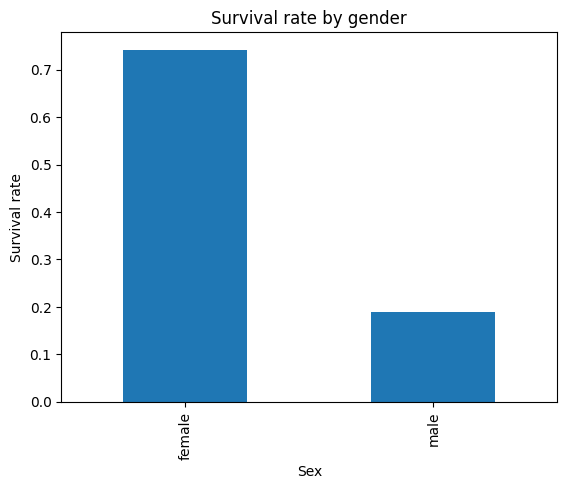

In [ ]:
print(df.groupby("Sex")["Survived"].mean())

df.groupby("Sex")["Survived"].mean().plot(kind="bar", title="Survival rate by gender")
plt.ylabel("Survival rate")
plt.show()

Did survival differ by gender?


Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


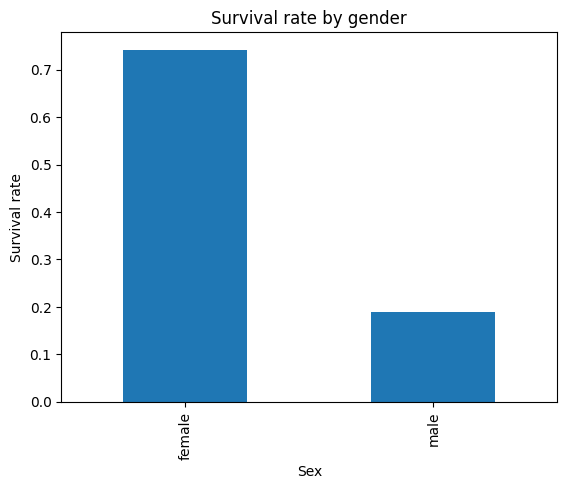

In [6]:
print(df.groupby("Sex")["Survived"].mean())

df.groupby("Sex")["Survived"].mean().plot(kind="bar", title="Survival rate by gender")
plt.ylabel("Survival rate")
plt.show()

Did survival differ by passenger class?


In [7]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Which columns have missing values? Fix Age.

In [8]:
median_age = df["Age"].median()
df["Age"] = df["Age"].fillna(median_age)

print(df["Age"].isnull().sum())   # should print 0

0


AgeGroup
Child     0.579710
Teen      0.410526
Adult     0.365957
Senior    0.227273
Name: Survived, dtype: float64


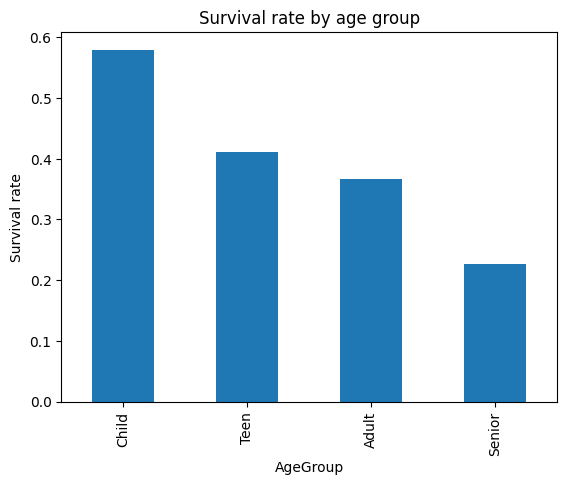

In [9]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 19, 60, 100],
    labels=["Child", "Teen", "Adult", "Senior"]
)

print(df.groupby("AgeGroup", observed=True)["Survived"].mean())

df.groupby("AgeGroup", observed=True)["Survived"].mean().plot(kind="bar", title="Survival rate by age group")
plt.ylabel("Survival rate")
plt.show()

Does survival differ by age group?